# Project 1: N-gram Smoothing, AWD-LSTM Reproduction and an Interpolated Hybrid Language Model
**NLP CS60075 Assignment II · Dataset: WikiText-2 · Bonus benchmark: BLiMP**

This notebook reproduces all three tasks end to end:

1. **Task 1:** a 4-gram language model with Add-k, Good-Turing and interpolated Kneser-Ney smoothing.
2. **Task 2:** a reproduction of the AWD-LSTM (Merity et al., 2017).
3. **Task 3:** a linear interpolation of the Kneser-Ney and AWD-LSTM models.

Every model is evaluated by perplexity on the WikiText-2 test split and by accuracy on 10 BLiMP paradigms.

### How to run
Select a GPU runtime (*Runtime → Change runtime type → T4 GPU*), then choose *Runtime → Run all*. The notebook is self-contained: it writes the project source files, installs the dependencies and downloads WikiText-2 and BLiMP from the Hugging Face Hub.

## 0. Configuration
* `QUICK = True` runs a short test of the whole pipeline. Its numbers are not meaningful.
* `QUICK = False` runs the full experiment, training the AWD-LSTM for 50 epochs.
* `USE_DRIVE = True` saves checkpoints to Google Drive, so an interrupted run resumes from the last completed epoch.

In [1]:
QUICK = False
EPOCHS = 50
USE_DRIVE = False

## 1. Environment setup

In [2]:
!nvidia-smi -L
!pip -q install datasets matplotlib

GPU 0: NVIDIA GeForce GTX 1650 (UUID: GPU-900f3e49-6ec6-bb6e-9034-da880c6494f6)


In [3]:
import os
os.makedirs('/content/project/src', exist_ok=True)
os.chdir('/content/project')
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    os.environ['CKPT_DIR'] = '/content/drive/MyDrive/nlp_p1_checkpoints'
os.environ['EPOCHS'] = str(EPOCHS)
RES = 'results_quick' if QUICK else 'results'
if QUICK:  # keep quick-test outputs separate from the real results
    os.environ.setdefault('CKPT_DIR', 'checkpoints_quick')
    os.environ.update(RESULTS_DIR=RES, CACHE_DIR='cache_quick')

## 2. Source code
The project modules: shared data pipeline and metrics, one module per task, and the figure script.

In [4]:
%%writefile src/common.py
"""shared code for all 3 tasks: data loading, tokenizer, vocab, blimp and metrics

everything that has to be exactly the same in task 1, 2 and 3 is kept here,
so the models are compared on the same tokens and the same blimp pairs.
"""
import json
import os
import re
from collections import Counter

import numpy as np

# folders, can be changed with environment variables
ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
CACHE_DIR = os.environ.get("CACHE_DIR", os.path.join(ROOT, "cache"))
RESULTS_DIR = os.environ.get("RESULTS_DIR", os.path.join(ROOT, "results"))
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

VOCAB_SIZE = 30000      # keep the 30k most frequent train tokens (+ <unk>)
MIN_COUNT = 2           # words seen less than 2 times in train become <unk>
UNK = "<unk>"

# the 10 blimp paradigms we use: the 6 suggested in the datasets document + 4 more
# so that morphology, syntax and semantics are all covered. the field shown in
# the results tables comes from blimp itself.
BLIMP_PARADIGMS = [
    # morphology
    "anaphor_gender_agreement",
    "determiner_noun_agreement_1",
    "regular_plural_subject_verb_agreement_1",
    "irregular_past_participle_adjectives",
    # syntax
    "wh_island",
    "adjunct_island",
    "drop_argument",
    # semantics / syntax-semantics
    "npi_present_1",
    "principle_A_domain_1",
    "existential_there_quantifiers_1",
]

# every blimp sentence is scored after this context. wikitext is one long stream
# with no <s> token, so a sentence normally starts right after a full stop.
BLIMP_CONTEXT = ["."]

# ---------------- tokenizer ----------------
# splits words, clitics ('s, n't, 're ...) and every punctuation mark into separate tokens
_TOKEN_RE = re.compile(r"\w+(?=n't)|n't|'\w+|\w+|[^\w\s]")


def normalize_wikitext(text):
    """undo wikitext's special formatting so it looks like normal english (same as blimp)"""
    text = text.replace(" @-@ ", "-").replace(" @,@ ", ",").replace(" @.@ ", ".")
    text = re.sub(r"n 't\b", "n't", text)      # "didn 't" -> "didn't" 
    return text


def tokenize(text):
    return _TOKEN_RE.findall(text.lower())


# ---------------- vocabulary ----------------
class Vocab:
    def __init__(self, itos):
        self.itos = list(itos)
        self.stoi = {w: i for i, w in enumerate(self.itos)}
        self.unk = self.stoi[UNK]

    def __len__(self):
        return len(self.itos)

    def encode(self, tokens):
        s, u = self.stoi, self.unk
        return np.array([s.get(t, u) for t in tokens], dtype=np.int64)


def _load_wikitext_tokens():
    from datasets import load_dataset
    ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")
    out = {}
    for split in ("train", "validation", "test"):
        # join all lines into one long stream, lines are not real sentences
        text = " ".join(ds[split]["text"])
        out[split] = tokenize(normalize_wikitext(text))
    return out


def get_data():
    """returns the vocab and the token ids of each split. cached after the first run"""
    vpath = os.path.join(CACHE_DIR, "vocab.json")
    paths = {s: os.path.join(CACHE_DIR, f"{s}.npy") for s in ("train", "validation", "test")}
    if os.path.exists(vpath) and all(os.path.exists(p) for p in paths.values()):
        with open(vpath) as f:
            vocab = Vocab(json.load(f))
        return vocab, {s: np.load(p) for s, p in paths.items()}

    # vocab is built from train only
    toks = _load_wikitext_tokens()
    counts = Counter(toks["train"])
    kept = [w for w, c in counts.most_common() if c >= MIN_COUNT and w != UNK][:VOCAB_SIZE]
    vocab = Vocab([UNK] + kept)
    ids = {s: vocab.encode(t) for s, t in toks.items()}
    with open(vpath, "w") as f:
        json.dump(vocab.itos, f)
    for s, p in paths.items():
        np.save(p, ids[s])
    return vocab, ids


# ---------------- blimp ----------------
def get_blimp(vocab):
    """loads the blimp pairs, tokenized with the same tokenizer and vocab as wikitext-2

    returns a list of dicts with paradigm, field, good ids and bad ids
    """
    from datasets import load_dataset
    data = []
    for p in BLIMP_PARADIGMS:
        ds = load_dataset("nyu-mll/blimp", p)["train"]
        for ex in ds:
            data.append({
                "paradigm": p,
                "field": ex["field"],
                "good": vocab.encode(tokenize(ex["sentence_good"])),
                "bad": vocab.encode(tokenize(ex["sentence_bad"])),
            })
    return data


def blimp_accuracy(data, good_scores, bad_scores):
    """accuracy = how often the good sentence gets the higher score, per paradigm and overall

    good_scores / bad_scores are length normalised log probs, one per pair
    """
    per = {}
    for ex, g, b in zip(data, good_scores, bad_scores):
        d = per.setdefault(ex["paradigm"], {"field": ex["field"], "correct": 0, "n": 0})
        d["correct"] += int(g > b)
        d["n"] += 1
    for d in per.values():
        d["acc"] = d["correct"] / d["n"]
    overall = sum(d["correct"] for d in per.values()) / sum(d["n"] for d in per.values())
    return {"overall": overall, "per_paradigm": per}


def ppl_from_logprobs(logp):
    """perplexity = exp(-average log prob)"""
    return float(np.exp(-np.mean(logp)))


def save_json(obj, name):
    path = os.path.join(RESULTS_DIR, name)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)
    return path


def load_json(name):
    with open(os.path.join(RESULTS_DIR, name)) as f:
        return json.load(f)


def format_blimp_table(results_by_model):
    """makes a markdown table of blimp accuracy, one column per model"""
    names = list(results_by_model)
    first = results_by_model[names[0]]["per_paradigm"]
    lines = ["| Paradigm | Field | " + " | ".join(names) + " |",
             "|---|---|" + "---|" * len(names)]
    for p in BLIMP_PARADIGMS:
        row = [p, first[p]["field"]] + [f"{results_by_model[n]['per_paradigm'][p]['acc']*100:.1f}" for n in names]
        lines.append("| " + " | ".join(row) + " |")
    lines.append("| **Overall** | | " + " | ".join(f"**{results_by_model[n]['overall']*100:.1f}**" for n in names) + " |")
    return "\n".join(lines)


Writing src/common.py


In [5]:
%%writefile src/task1_ngram.py
"""task 1 - n-gram language model with smoothing

builds 1 to 4-gram counts from the train split and tries 5 smoothing methods:
  - add-k with k = 1, 0.5, 0.1
  - good-turing (katz backoff, counts r <= 5 are discounted)
  - interpolated kneser-ney with d = 0.75, lambda tuned on validation

everything is done with numpy arrays so it runs fast. each n-gram (w1..wn)
is turned into one int64 number  w1*B^(n-1) + ... + wn  where B = vocab size + 1
(the extra id is a padding token we only use as left context at the start).
looking up a count is then just a binary search in a sorted array.

run:  python src/task1_ngram.py
"""
import os
import sys
import time

import numpy as np

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from common import (BLIMP_CONTEXT, CACHE_DIR, RESULTS_DIR, blimp_accuracy,  # noqa: E402
                    format_blimp_table, get_blimp, get_data, ppl_from_logprobs, save_json)

MAX_N = 4
KN_DISCOUNT = 0.75
KN_LAMBDAS = [round(0.1 * i, 1) for i in range(1, 10)]
ADD_KS = [1.0, 0.5, 0.1]
GT_MAX_R = 5
GT_MIN_BACKOFF = 1e-3   # min backoff mass for katz, explained in KatzGoodTuring


# ---------------- count tables ----------------
class Table:
    """sorted keys -> values, lookup works on whole arrays at once"""

    def __init__(self, keys, vals):
        self.keys, self.vals = keys, vals

    def __getitem__(self, q):
        # binary search, keys that are not in the table get value 0
        idx = np.searchsorted(self.keys, q)
        idx[idx == len(self.keys)] = 0
        found = self.keys[idx] == q
        return np.where(found, self.vals[idx], 0), found


def group_by_history(keys, vals, B):
    """for each history h: total count c(h) and number of different next words"""
    prefix = keys // B                          # history part of the key, already sorted
    starts = np.flatnonzero(np.r_[True, prefix[1:] != prefix[:-1]])
    hk = prefix[starts]
    hsum = np.add.reduceat(vals, starts)
    htypes = np.diff(np.r_[starts, len(keys)])
    return Table(hk, hsum.astype(np.float64)), Table(hk, htypes.astype(np.float64)), starts


class NGramCounts:
    def __init__(self, ids, V, max_n=MAX_N):
        self.V, self.B, self.PAD, self.N, self.max_n = V, V + 1, V, len(ids), max_n
        # raw counts for every order, by sliding a window over the token stream
        self.raw = {}
        for n in range(1, max_n + 1):
            k = np.zeros(len(ids) - n + 1, dtype=np.int64)
            for j in range(n):
                k = k * self.B + ids[j: len(ids) - n + 1 + j]
            u, c = np.unique(k, return_counts=True)
            self.raw[n] = Table(u, c.astype(np.float64))
        # continuation counts for kneser-ney: in how many different contexts does g appear
        self.cont = {}
        for m in range(1, max_n):
            suffix = self.raw[m + 1].keys % (self.B ** m)
            u, c = np.unique(suffix, return_counts=True)
            self.cont[m] = Table(u, c.astype(np.float64))

    def describe(self):
        return {n: len(t.keys) for n, t in self.raw.items()}


# ---------------- smoothing methods ----------------
class AddK:
    def __init__(self, C, n, k):
        self.C, self.n, self.k = C, n, k
        self.name = f"Add-k (k={k:g})"
        if n > 1:
            self.hsum, _, _ = group_by_history(C.raw[n].keys, C.raw[n].vals, C.B)

    def prob(self, g):
        # P(w|h) = (c(h,w) + k) / (c(h) + k*V)
        C, k, V = self.C, self.k, self.C.V
        c, _ = C.raw[self.n][g]
        if self.n == 1:
            return (c + k) / (C.N + k * V)
        ch, _ = self.hsum[g // C.B]
        return (c + k) / (ch + k * V)


class KatzGoodTuring:
    """katz backoff using good-turing discounted counts for r <= 5

    r* = (r+1) N_{r+1} / N_r, and katz's discount ratio is
    d_r = (r*/r - (k+1)N_{k+1}/N_1) / (1 - (k+1)N_{k+1}/N_1) with k = 5
    seen n-gram:   P(w|h) = d_c * c(h,w) / c(h)
    unseen n-gram: P(w|h) = alpha(h) * P_katz(w|h'), alpha makes it sum to 1
    unigrams are just c(w)/N since every vocab word appears in train.

    problem we found: counts above 5 are not discounted, so if every word seen
    after some history appeared more than 5 times, there is no mass left for
    unseen words and they get probability 0 (perplexity becomes infinite).
    to fix this, such histories keep at least min_backoff mass and the seen
    probabilities are scaled down so it still sums to 1.
    """

    def __init__(self, C, n, min_backoff=GT_MIN_BACKOFF):
        self.C, self.n, self.min_backoff = C, n, min_backoff
        self.name = "Good-Turing (Katz)" if min_backoff > 0 else "Good-Turing (Katz, no floor)"
        self.disc, self.hsum, self.alpha, self.nr, self.scale = {}, {}, {}, {}, {}
        # go from low order to high order, since alpha for order m needs P for order m-1
        for m in range(2, n + 1):
            t = C.raw[m]
            # N_r = how many n-grams occur exactly r times
            r_counts = np.bincount(t.vals.astype(np.int64), minlength=GT_MAX_R + 3)
            Nr = r_counts.astype(np.float64)
            kk = GT_MAX_R
            common = (kk + 1) * Nr[kk + 1] / Nr[1]
            # discount ratio d_r for r = 1..5
            d = np.ones(GT_MAX_R + 1)
            for r in range(1, kk + 1):
                rstar = (r + 1) * Nr[r + 1] / Nr[r]
                d[r] = (rstar / r - common) / (1 - common)
            d = np.where((d > 0) & (d <= 1), d, 1.0)
            self.disc[m] = d
            self.nr[m] = {"N_r": Nr[1:kk + 2].tolist(), "d_r": d[1:].tolist()}
            hsum, _, starts = group_by_history(t.keys, t.vals, C.B)
            self.hsum[m] = hsum
            # leftover mass beta(h) = 1 - sum of discounted probs of seen words
            pdisc = self._dstar(m, t.vals) / hsum.vals.repeat(np.diff(np.r_[starts, len(t.keys)]))
            lower = self.prob(t.keys % (C.B ** (m - 1)), m - 1)
            beta = np.clip(1.0 - np.add.reduceat(pdisc, starts), 0, None)
            new_beta = np.maximum(beta, self.min_backoff)
            self.scale[m] = Table(hsum.keys, (1 - new_beta) / (1 - beta))   # scale down seen probs
            # alpha(h) = beta(h) / (1 - lower-order prob of the seen words)
            den = 1.0 - np.add.reduceat(lower, starts)
            alpha = new_beta / np.clip(den, 1e-12, None)
            self.alpha[m] = Table(hsum.keys, alpha)
            self.nr[m]["histories_floored"] = int((beta < self.min_backoff).sum())

    def _dstar(self, m, c):
        # discounted count: d_r * r for r <= 5, raw count otherwise
        ci = c.astype(np.int64)
        d = np.where(ci <= GT_MAX_R, self.disc[m][np.minimum(ci, GT_MAX_R)], 1.0)
        return d * c

    def prob(self, g, m=None):
        m = self.n if m is None else m
        C = self.C
        if m == 1:
            c, _ = C.raw[1][g]
            return c / C.N
        c, seen = C.raw[m][g]
        h = g // C.B
        lower = self.prob(g % (C.B ** (m - 1)), m - 1)
        ch, _ = self.hsum[m][h]
        a, hseen = self.alpha[m][h]
        a = np.where(hseen, a, 1.0)                 # history never seen -> just use lower order
        with np.errstate(divide="ignore", invalid="ignore"):
            p_seen = self._dstar(m, c) / ch * self.scale[m][h][0]
        return np.where(seen, p_seen, a * lower)


class InterpolatedKN:
    """interpolated kneser-ney with discount d and an extra weight lambda

    for order m >= 2 (raw counts at the top order, continuation counts below):
      P_KN(w|h) = max(c(h,w) - d, 0)/c(h) + d * N1+(h .)/c(h) * P_lower(w|h')
      P(w|h)    = lambda * P_KN(w|h) + (1 - lambda) * P_lower(w|h')
    lambda = 1 is normal interpolated kneser-ney. if h was never seen we just
    use P_lower. the unigram level uses continuation counts mixed with uniform.
    """

    def __init__(self, C, n, lam, d=KN_DISCOUNT):
        self.C, self.n, self.lam, self.d = C, n, lam, d
        self.name = f"Kneser-Ney (d={d}, λ={lam:g})"
        self.tab, self.hsum, self.htypes = {}, {}, {}
        # top order uses raw counts, lower orders use continuation counts
        for m in range(1, n + 1):
            t = C.raw[m] if m == n else C.cont[m]
            self.tab[m] = t
            if m > 1:
                self.hsum[m], self.htypes[m], _ = group_by_history(t.keys, t.vals, C.B)
        t1 = self.tab[1]
        self.s1, self.ty1 = t1.vals.sum(), len(t1.keys)

    def prob(self, g, m=None):
        m = self.n if m is None else m
        C, d = self.C, self.d
        if m == 1:
            # discounted continuation unigram + leftover mass spread uniformly
            c, _ = self.tab[1][g]
            return np.maximum(c - d, 0) / self.s1 + d * self.ty1 / self.s1 / C.V
        c, _ = self.tab[m][g]
        h = g // C.B
        S, hseen = self.hsum[m][h]
        T, _ = self.htypes[m][h]
        lower = self.prob(g % (C.B ** (m - 1)), m - 1)
        with np.errstate(divide="ignore", invalid="ignore"):
            pkn = np.maximum(c - d, 0) / S + d * T / S * lower
        return np.where(hseen, self.lam * pkn + (1 - self.lam) * lower, lower)


# ---------------- helpers for scoring text ----------------
def stream_keys(ids, n, B, PAD):
    """n-gram keys for predicting ids[1:], with up to n-1 words of left context"""
    padded = np.concatenate([np.full(n - 1, PAD, dtype=np.int64), ids])
    M = len(ids) - 1
    k = np.zeros(M, dtype=np.int64)
    for j in range(n):          # the word we predict, ids[t], is at padded[t + n - 1]
        k = k * B + padded[1 + j: 1 + j + M]
    return k


def sentence_keys(sentences, ctx, n, B, PAD):
    """keys for every word of every sentence, each sentence starts after ctx"""
    keys, lengths = [], []
    for s in sentences:
        seq = np.concatenate([ctx, s])
        k = stream_keys(seq, n, B, PAD)[len(ctx) - 1:]     # keep only the sentence words
        keys.append(k)
        lengths.append(len(s))
    return np.concatenate(keys), np.array(lengths)


def logp(model, keys):
    return np.log(np.clip(model.prob(keys), 1e-300, None))


def split_by_lengths(arr, lengths):
    return np.split(arr, np.cumsum(lengths)[:-1])


# ---------------- main ----------------
def main():
    t0 = time.time()
    vocab, ids = get_data()
    V = len(vocab)
    C = NGramCounts(ids["train"], V)
    print(f"vocab {V} | train tokens {C.N} | unique n-grams {C.describe()} | {time.time()-t0:.1f}s", flush=True)

    def eval_keys(split, n):
        return stream_keys(ids[split], n, C.B, C.PAD)

    keys = {(s, n): eval_keys(s, n) for s in ("validation", "test") for n in range(1, MAX_N + 1)}

    # sanity check: probabilities over the whole vocab should sum to 1
    rng = np.random.default_rng(0)
    probe_ctx = ids["validation"][rng.integers(3, 10000, size=3)]

    def check_norm(model, n):
        sums = []
        for c in probe_ctx:
            ctx = np.array([c] * (n - 1), dtype=np.int64)
            base = 0
            for x in ctx:
                base = base * C.B + x
            sums.append(model.prob(base * C.B + np.arange(V, dtype=np.int64)).sum())
        return sums

    # kneser-ney: grid search lambda on validation, separately for each order
    kn_tuning = {}
    best_lam = {}
    for n in range(2, MAX_N + 1):
        kn_tuning[n] = {}
        for lam in KN_LAMBDAS + [1.0]:
            kn_tuning[n][lam] = ppl_from_logprobs(logp(InterpolatedKN(C, n, lam), keys[("validation", n)]))
        best_lam[n] = min(KN_LAMBDAS, key=lambda l: kn_tuning[n][l])     # 1.0 is only for reference, not picked
        print(f"KN n={n}: val PPL by lambda " +
              ", ".join(f"{l:g}:{p:.1f}" for l, p in kn_tuning[n].items()) + f" -> best {best_lam[n]}", flush=True)

    # evaluate every smoothing method for n = 1..4
    def make(variant, n):
        if variant.startswith("addk"):
            return AddK(C, n, float(variant[4:]))
        if variant == "gt":
            return KatzGoodTuring(C, n)
        if variant == "kn":
            return InterpolatedKN(C, n, best_lam.get(n, 1.0)) if n > 1 else InterpolatedKN(C, 1, 1.0)
        raise ValueError(variant)

    variants = [f"addk{k:g}" for k in ADD_KS] + ["gt", "kn"]
    table = {}
    models = {}
    for v in variants:
        for n in range(1, MAX_N + 1):
            m = make(v, n)
            models[(v, n)] = m
            table[(v, n)] = {s: ppl_from_logprobs(logp(m, keys[(s, n)])) for s in ("validation", "test")}
            print(f"{m.name:28s} n={n}: val {table[(v, n)]['validation']:10.2f} | "
                  f"test {table[(v, n)]['test']:10.2f}", flush=True)

    # count how many tokens get probability 0 with plain katz (no min backoff)
    gt_raw = {}
    for n in range(2, MAX_N + 1):
        m = KatzGoodTuring(C, n, min_backoff=0.0)
        p = m.prob(keys[("validation", n)]), m.prob(keys[("test", n)])
        gt_raw[n] = {"val_zero_prob_tokens": int((p[0] <= 0).sum()), "test_zero_prob_tokens": int((p[1] <= 0).sum())}
        print(f"Katz without floor n={n}: zero-probability tokens val/test = "
              f"{gt_raw[n]['val_zero_prob_tokens']}/{gt_raw[n]['test_zero_prob_tokens']} -> PPL = inf", flush=True)

    norm = {models[(v, MAX_N)].name: check_norm(models[(v, MAX_N)], MAX_N) for v in variants}
    print("normalisation check (sum_w P(w|h), should be 1):",
          {k: [round(x, 6) for x in s] for k, s in norm.items()}, flush=True)

    # pick the best 4-gram model by validation perplexity, use it for blimp
    best_v = min(variants, key=lambda v: table[(v, MAX_N)]["validation"])
    best = models[(best_v, MAX_N)]
    print(f"best variant by validation PPL: {best.name}", flush=True)

    blimp = get_blimp(vocab)
    ctx = vocab.encode(BLIMP_CONTEXT)
    gk, gl = sentence_keys([e["good"] for e in blimp], ctx, MAX_N, C.B, C.PAD)
    bk, bl = sentence_keys([e["bad"] for e in blimp], ctx, MAX_N, C.B, C.PAD)
    blimp_res = {}
    for v in variants:                     # only the best one is required, rest are extra
        m = models[(v, MAX_N)]
        g = split_by_lengths(logp(m, gk), gl)
        b = split_by_lengths(logp(m, bk), bl)
        blimp_res[m.name] = blimp_accuracy(blimp, [x.mean() for x in g], [x.mean() for x in b])
        if v == "kn":                      # save per-word scores, task 3 needs them
            np.save(os.path.join(CACHE_DIR, "task1_kn_blimp_good.npy"), np.array(g, dtype=object), allow_pickle=True)
            np.save(os.path.join(CACHE_DIR, "task1_kn_blimp_bad.npy"), np.array(b, dtype=object), allow_pickle=True)
    kn = models[("kn", MAX_N)]
    for s in ("validation", "test"):
        np.save(os.path.join(CACHE_DIR, f"task1_kn_{s}_logprobs.npy"), logp(kn, keys[(s, MAX_N)]))

    # save everything to json
    res = {
        "vocab_size": V, "train_tokens": int(C.N), "unique_ngrams": C.describe(),
        "eval_tokens": {s: int(len(ids[s]) - 1) for s in ("validation", "test")},
        "kn_lambda_tuning": {str(n): {str(l): p for l, p in d.items()} for n, d in kn_tuning.items()},
        "kn_best_lambda": best_lam,
        "good_turing_stats": {n: models[("gt", n)].nr[n] for n in range(2, MAX_N + 1)},
        "good_turing_min_backoff": GT_MIN_BACKOFF,
        "good_turing_without_floor": gt_raw,
        "perplexity": {f"{models[(v, n)].name} | n={n}": table[(v, n)] for v in variants for n in range(1, MAX_N + 1)},
        "main_table_4gram": {models[(v, MAX_N)].name: table[(v, MAX_N)] for v in variants},
        "best_variant": best.name,
        "blimp": blimp_res,
        "normalisation_check": norm,
        "runtime_s": time.time() - t0,
    }
    save_json(res, "task1_results.json")

    # and write the results tables as markdown
    md = ["# Task 1 - Smoothed n-gram LM results", "",
          f"Vocabulary {V} (30,000 + `<unk>`), {C.N:,} training tokens; "
          f"evaluated on {len(ids['test'])-1:,} test tokens.", "",
          "## Perplexity of the five smoothing variants (4-gram)", "",
          "| Variant | Validation PPL | Test PPL |", "|---|---|---|"]
    for v in variants:
        r = table[(v, MAX_N)]
        md.append(f"| {models[(v, MAX_N)].name} | {r['validation']:.2f} | {r['test']:.2f} |")
    md += ["", "## Test perplexity by n-gram order", "",
           "| Variant | " + " | ".join(f"n={n}" for n in range(1, MAX_N + 1)) + " |",
           "|---|" + "---|" * MAX_N]
    for v in variants:
        md.append(f"| {models[(v, MAX_N)].name.split(' (')[0] + (' ' + v[4:] if v.startswith('addk') else '')} | " +
                  " | ".join(f"{table[(v, n)]['test']:.1f}" for n in range(1, MAX_N + 1)) + " |")
    md += ["", f"Good-Turing note: pure Katz back-off (no floor) gives zero probability to "
           f"{gt_raw[MAX_N]['test_zero_prob_tokens']} test tokens at n={MAX_N} (perplexity = ∞), because histories "
           f"whose continuations all occur > {GT_MAX_R} times keep no back-off mass; the reported numbers use a "
           f"minimum back-off mass of {GT_MIN_BACKOFF:g} for such histories."]
    md += ["", "## Kneser-Ney λ grid search (validation PPL; λ=1.0 = textbook IKN, reference only)", "",
           "| n | " + " | ".join(f"λ={l:g}" for l in KN_LAMBDAS + [1.0]) + " | best λ |",
           "|---|" + "---|" * (len(KN_LAMBDAS) + 2)]
    for n in range(2, MAX_N + 1):
        md.append(f"| {n} | " + " | ".join(f"{kn_tuning[n][l]:.1f}" for l in KN_LAMBDAS + [1.0]) + f" | {best_lam[n]} |")
    md += ["", f"## BLiMP accuracy (%) - best variant by validation PPL: **{best.name}**", "",
           format_blimp_table({best.name: blimp_res[best.name]}), "",
           "### BLiMP accuracy (%) for every 4-gram variant (supplementary)", "",
           format_blimp_table(blimp_res)]
    with open(os.path.join(RESULTS_DIR, "task1_results.md"), "w") as f:
        f.write("\n".join(md) + "\n")
    print("\n".join(md))
    print(f"total time {time.time()-t0:.0f}s")


if __name__ == "__main__":
    main()


Writing src/task1_ngram.py


In [6]:
%%writefile src/task2_awd_lstm.py
"""task 2 - reproducing the AWD-LSTM paper (Merity, Keskar & Socher, 2017)

model:          3 layer lstm, embedding 400, hidden 1150, embedding and softmax weights are tied
regularisation: dropconnect 0.5 on the hidden-to-hidden weights, embedding dropout 0.1,
                output dropout 0.4. the rest is the paper's wikitext-2 setting: input dropout 0.65,
                dropout between layers 0.2, AR (alpha 2), TAR (beta 1), weight decay 1.2e-6,
                and random bptt length
optimiser:      NT-ASGD with lr 30, n = 5, checked once per epoch, clip 0.25, batch 80, bptt 70
change:         we train ~50 epochs instead of 500-750 like the paper (not enough time/compute)

how to run:
    python src/task2_awd_lstm.py train  [--epochs 50] [--nhid 1150]
    python src/task2_awd_lstm.py eval            # test ppl + blimp, also saves scores for task 3
"""
import argparse
import math
import os
import sys
import time

import numpy as np

# helps avoid memory fragmentation on a small gpu
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
import torch  # noqa: E402
import torch.nn as nn  # noqa: E402
import torch.nn.functional as F  # noqa: E402

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from common import (CACHE_DIR, RESULTS_DIR, blimp_accuracy, format_blimp_table,  # noqa: E402
                    get_blimp, get_data, ppl_from_logprobs, save_json, BLIMP_CONTEXT)

CKPT_DIR = os.environ.get("CKPT_DIR", os.path.join(os.path.dirname(RESULTS_DIR), "checkpoints"))
os.makedirs(CKPT_DIR, exist_ok=True)


# ---------------- model parts ----------------
class LockedDropout(nn.Module):
    """variational dropout: same dropout mask used at every time step"""

    def forward(self, x, p):
        if not self.training or p == 0:
            return x
        mask = x.new_empty(1, x.size(1), x.size(2)).bernoulli_(1 - p) / (1 - p)
        return x * mask


def embedded_dropout(embed, words, p):
    """embedding dropout: drops whole words (rows of the embedding matrix)"""
    if embed.training and p > 0:
        mask = embed.weight.new_empty(embed.weight.size(0), 1).bernoulli_(1 - p) / (1 - p)
        weight = embed.weight * mask
    else:
        weight = embed.weight
    return F.embedding(words, weight)


class WeightDropLSTM(nn.Module):
    """one lstm layer with dropconnect on the hidden-to-hidden matrix W_hh

    a new mask for W_hh is sampled once per batch and used for all time steps,
    same as the paper. we pass the dropped weight straight to the cudnn lstm
    kernel, so it is just as fast as a normal nn.LSTM.
    """

    def __init__(self, ninp, nhid, wdrop):
        super().__init__()
        self.ninp, self.nhid, self.wdrop = ninp, nhid, wdrop
        # same init as pytorch's nn.LSTM
        k = 1.0 / math.sqrt(nhid)
        self.w_ih = nn.Parameter(torch.empty(4 * nhid, ninp).uniform_(-k, k))
        self.w_hh = nn.Parameter(torch.empty(4 * nhid, nhid).uniform_(-k, k))
        self.b_ih = nn.Parameter(torch.empty(4 * nhid).uniform_(-k, k))
        self.b_hh = nn.Parameter(torch.empty(4 * nhid).uniform_(-k, k))

    def forward(self, x, hidden):
        # dropconnect: dropout on the weights, not on the activations
        w_hh = F.dropout(self.w_hh, p=self.wdrop, training=self.training)
        out, h, c = torch._VF.lstm(x, hidden, [self.w_ih, w_hh, self.b_ih, self.b_hh],
                                   True, 1, 0.0, self.training, False, False)
        return out, (h, c)


class AWDLSTM(nn.Module):
    def __init__(self, ntoken, ninp=400, nhid=1150, nlayers=3, dropout=0.4, dropouth=0.2,
                 dropouti=0.65, dropoute=0.1, wdrop=0.5):
        super().__init__()
        self.ntoken, self.ninp, self.nhid, self.nlayers = ntoken, ninp, nhid, nlayers
        self.dropout, self.dropouth, self.dropouti, self.dropoute = dropout, dropouth, dropouti, dropoute
        self.lockdrop = LockedDropout()
        self.encoder = nn.Embedding(ntoken, ninp)
        # last layer outputs 400 (= embedding size) so we can tie the weights
        self.rnns = nn.ModuleList([
            WeightDropLSTM(ninp if l == 0 else nhid, nhid if l != nlayers - 1 else ninp, wdrop)
            for l in range(nlayers)])
        self.decoder = nn.Linear(ninp, ntoken)
        self.decoder.weight = self.encoder.weight          # weight tying
        self.encoder.weight.data.uniform_(-0.1, 0.1)
        self.decoder.bias.data.zero_()

    def init_hidden(self, bsz):
        w = next(self.parameters())
        return [(w.new_zeros(1, bsz, r.nhid), w.new_zeros(1, bsz, r.nhid)) for r in self.rnns]

    def forward(self, inp, hidden):
        # embedding -> dropout -> 3 lstm layers (dropout between them) -> output dropout
        emb = embedded_dropout(self.encoder, inp, self.dropoute if self.training else 0)
        x = self.lockdrop(emb, self.dropouti)
        new_hidden, raw_outputs, outputs = [], [], []
        for l, rnn in enumerate(self.rnns):
            x, h = rnn(x, hidden[l])
            new_hidden.append(h)
            raw_outputs.append(x)
            if l != self.nlayers - 1:
                x = self.lockdrop(x, self.dropouth)
                outputs.append(x)
        out = self.lockdrop(x, self.dropout)               # output dropout
        outputs.append(out)
        # we return hidden states, not logits. the caller applies the decoder
        # (or chunked_ce during training)
        return out, new_hidden, raw_outputs, outputs


class ChunkedSoftmaxCE(torch.autograd.Function):
    """cross entropy of softmax(h W^T + b), done in chunks of rows to save memory

    gives exactly the same result as F.cross_entropy(F.linear(h, W, b), y), but
    the full (T*B x 30001) logit matrix never has to be in memory, which is how
    the 1150 model fits on a 4 GB gpu. we work out the gradients in the forward
    pass chunk by chunk so nothing has to be recomputed in backward.
    """

    @staticmethod
    def forward(ctx, h, W, b, y, chunk):
        n = h.size(0)
        gh, gW, gb = torch.empty_like(h), torch.zeros_like(W), torch.zeros_like(b)
        total = h.new_zeros(())
        for s in range(0, n, chunk):
            hc, yc = h[s:s + chunk], y[s:s + chunk]
            logits = torch.addmm(b, hc, W.t())
            lse = torch.logsumexp(logits, dim=1)
            total += (lse - logits.gather(1, yc[:, None]).squeeze(1)).sum()
            # gradient wrt logits is softmax - one_hot(target)
            g = torch.softmax(logits, dim=1)
            g[torch.arange(len(yc), device=y.device), yc] -= 1
            gh[s:s + chunk] = g @ W
            gW.addmm_(g.t(), hc)
            gb += g.sum(0)
            del logits, g
        ctx.save_for_backward(gh, gW, gb)
        ctx.n = n
        return total / n

    @staticmethod
    def backward(ctx, grad_out):
        # gradients were already computed in forward, just scale them
        gh, gW, gb = ctx.saved_tensors
        s = grad_out / ctx.n
        return gh * s, gW * s, gb * s, None, None


def chunked_ce(h, W, b, y, chunk=2048):
    return ChunkedSoftmaxCE.apply(h, W, b, y, chunk)


def repackage(h):
    # cut the graph so backprop stops at the start of the batch
    return [(a.detach(), b.detach()) for a, b in h]


def batchify(ids, bsz, device):
    n = len(ids) // bsz
    # split the stream into bsz columns, shape (T, B)
    data = torch.from_numpy(ids[: n * bsz]).view(bsz, n).t().contiguous()
    return data.to(device)


# ---------------- evaluation ----------------
@torch.no_grad()
def evaluate_loss(model, data, bptt=70):
    """average loss over the validation stream, used after every epoch"""
    model.eval()
    hidden = model.init_hidden(data.size(1))
    total, count = 0.0, 0
    for i in range(0, data.size(0) - 1, bptt):
        seq = min(bptt, data.size(0) - 1 - i)
        x, y = data[i:i + seq], data[i + 1:i + 1 + seq]
        out, hidden, _, _ = model(x, hidden)
        logits = model.decoder(out)
        total += F.cross_entropy(logits.view(-1, model.ntoken), y.reshape(-1), reduction="sum").item()
        count += y.numel()
    return total / count


@torch.no_grad()
def token_logprobs(model, ids, device, bptt=70):
    """log P(w_t | everything before) for every token except the first, batch size 1

    these are the same positions that task 1 scores, so task 3 can mix them word by word
    """
    model.eval()
    data = torch.from_numpy(ids).to(device).view(-1, 1)
    hidden = model.init_hidden(1)
    chunks = []
    for i in range(0, data.size(0) - 1, bptt):
        seq = min(bptt, data.size(0) - 1 - i)
        x, y = data[i:i + seq], data[i + 1:i + 1 + seq]
        h, hidden, _, _ = model(x, hidden)
        lp = F.log_softmax(model.decoder(h), dim=-1).gather(-1, y.unsqueeze(-1)).view(-1)
        chunks.append(lp.cpu().numpy())
    return np.concatenate(chunks).astype(np.float64)


@torch.no_grad()
def sentence_token_logprobs(model, sentences, device, bsz=100):
    """log prob of every word of every blimp sentence, each starting after BLIMP_CONTEXT

    returns one array per sentence (one value per word)
    """
    model.eval()
    res = [None] * len(sentences)
    # sort by length so each batch needs little padding
    order = np.argsort([len(s) for s in sentences])
    for b in range(0, len(order), bsz):
        idx = order[b:b + bsz]
        seqs = [np.concatenate([CTX_IDS, sentences[i]]) for i in idx]
        L = max(len(s) for s in seqs)
        x = torch.zeros(L, len(seqs), dtype=torch.long)
        for j, s in enumerate(seqs):
            x[: len(s), j] = torch.from_numpy(s)
        x = x.to(device)
        out, _, _, _ = model(x[:-1], model.init_hidden(len(seqs)))
        lp = F.log_softmax(model.decoder(out), dim=-1).gather(-1, x[1:].unsqueeze(-1)).squeeze(-1).cpu().numpy()
        # keep only the scores of the sentence words (skip context and padding)
        for j, i in enumerate(idx):
            n_ctx = len(CTX_IDS)
            res[i] = lp[n_ctx - 1: len(seqs[j]) - 1, j].astype(np.float64)
    return res


CTX_IDS = None  # set in evaluate() once we have the vocab


# ---------------- training ----------------
def train(args):
    torch.manual_seed(args.seed)
    np.random.seed(args.seed)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    vocab, ids = get_data()
    train_data = batchify(ids["train"], args.batch_size, device)
    val_data = batchify(ids["validation"], 10, device)

    model = AWDLSTM(len(vocab), args.emsize, args.nhid, 3, args.dropout, args.dropouth,
                    args.dropouti, args.dropoute, args.wdrop).to(device)
    params = list(model.parameters())
    print(f"params: {sum(p.numel() for p in params)/1e6:.1f}M | vocab {len(vocab)} | device {device}", flush=True)
    # starts as plain sgd, the averaging part of nt-asgd is done by hand below
    optimizer = torch.optim.SGD(params, lr=args.lr, weight_decay=args.wdecay)

    state = {"epoch": 0, "val_history": [], "asgd": False, "asgd_epoch": None,
             "avg": None, "n_avg": 0, "best_val": float("inf"), "log": []}
    last_path = os.path.join(CKPT_DIR, "awd_last.pt")
    best_path = os.path.join(CKPT_DIR, "awd_best.pt")
    # resume from the last checkpoint if there is one
    if os.path.exists(last_path) and not args.restart:
        ck = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"])
        optimizer.load_state_dict(ck["optimizer"])
        state = ck["state"]
        torch.set_rng_state(ck["rng"].cpu())
        np.random.set_state(ck["np_rng"])
        print(f"resumed from epoch {state['epoch']}", flush=True)

    def swap_in_average():
        """put the averaged asgd weights into the model and return the normal ones"""
        raw = [p.data.clone() for p in params]
        for p, a in zip(params, state["avg"]):
            p.data.copy_(a)
        return raw

    for epoch in range(state["epoch"] + 1, args.epochs + 1):
        model.train()
        t0 = time.time()
        hidden = model.init_hidden(args.batch_size)
        total_loss, n_batches, i = 0.0, 0, 0
        while i < train_data.size(0) - 2:
            # random bptt length, like section 4.1 of the paper
            bptt = args.bptt if np.random.random() < 0.95 else args.bptt / 2
            seq_len = max(5, int(np.random.normal(bptt, 5)))
            seq_len = min(seq_len, args.bptt + 20, train_data.size(0) - 1 - i)
            for g in optimizer.param_groups:               # scale lr with the sequence length
                g["lr"] = args.lr * seq_len / args.bptt
            x, y = train_data[i:i + seq_len], train_data[i + 1:i + 1 + seq_len]
            hidden = repackage(hidden)
            optimizer.zero_grad(set_to_none=True)
            out, hidden, raw_outs, outs = model(x, hidden)
            raw_loss = chunked_ce(out.reshape(-1, model.ninp), model.decoder.weight,
                                  model.decoder.bias, y.reshape(-1))
            loss = raw_loss
            loss = loss + args.alpha * outs[-1].pow(2).mean()                              # AR: keep activations small
            loss = loss + args.beta * (raw_outs[-1][1:] - raw_outs[-1][:-1]).pow(2).mean()  # TAR: keep them smooth over time
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, args.clip)
            optimizer.step()
            if state["asgd"]:                                # asgd: keep a running average of the weights
                state["n_avg"] += 1
                k = 1.0 / state["n_avg"]
                for a, p in zip(state["avg"], params):
                    a.add_(p.data - a, alpha=k)
            total_loss += raw_loss.item()
            n_batches += 1
            i += seq_len
            if n_batches % args.log_interval == 0:
                cur = total_loss / n_batches
                print(f"  ep {epoch} batch {n_batches} | train loss {cur:.3f} ppl {math.exp(cur):.1f}"
                      f" | {(time.time()-t0)/n_batches*1000:.0f} ms/batch", flush=True)
            if args.max_batches and n_batches >= args.max_batches:
                break

        # validation, using the averaged weights once asgd has started
        if state["asgd"]:
            raw = swap_in_average()
        val_loss = evaluate_loss(model, val_data, args.bptt)
        train_ppl = math.exp(total_loss / n_batches)
        entry = {"epoch": epoch, "train_ppl": train_ppl, "val_ppl": math.exp(val_loss),
                 "asgd": state["asgd"], "time_s": time.time() - t0}
        state["log"].append(entry)
        print(f"| end of epoch {epoch} | {entry['time_s']:.0f}s | train ppl {train_ppl:.2f} "
              f"| val ppl {entry['val_ppl']:.2f} | {'ASGD' if state['asgd'] else 'SGD'}", flush=True)
        if val_loss < state["best_val"]:
            state["best_val"] = val_loss
            torch.save({"model": model.state_dict(), "args": vars(args), "epoch": epoch}, best_path)
            print("  saved best model", flush=True)
        if state["asgd"]:
            for p, r in zip(params, raw):
                p.data.copy_(r)

        # nt-asgd: switch to averaging if val loss is worse than the best from more
        # than n epochs ago (algorithm 1 in the paper, checked once per epoch)
        if (not state["asgd"] and len(state["val_history"]) > args.nonmono
                and val_loss > min(state["val_history"][:-args.nonmono])):
            print(f"  >>> non-monotone trigger: switching to ASGD at epoch {epoch}", flush=True)
            state["asgd"], state["asgd_epoch"] = True, epoch
            state["avg"] = [p.data.clone() for p in params]
            state["n_avg"] = 1
        state["val_history"].append(val_loss)
        state["epoch"] = epoch
        # save a checkpoint every epoch so training can be resumed
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                    "state": state, "rng": torch.get_rng_state(),
                    "np_rng": np.random.get_state()}, last_path)
        save_json({"args": vars(args), "log": state["log"], "asgd_epoch": state["asgd_epoch"]},
                  "task2_training_log.json")


# ---------------- final evaluation ----------------
def evaluate(args):
    global CTX_IDS
    device = "cuda" if torch.cuda.is_available() else "cpu"
    vocab, ids = get_data()
    CTX_IDS = vocab.encode(BLIMP_CONTEXT)
    # load the checkpoint with the best validation perplexity
    ck = torch.load(os.path.join(CKPT_DIR, "awd_best.pt"), map_location=device, weights_only=False)
    a = ck["args"]
    model = AWDLSTM(len(vocab), a["emsize"], a["nhid"], 3, a["dropout"], a["dropouth"],
                    a["dropouti"], a["dropoute"], a["wdrop"]).to(device)
    model.load_state_dict(ck["model"])
    print(f"loaded best checkpoint from epoch {ck['epoch']}", flush=True)

    # perplexity on validation and test, also save per-word scores for task 3
    res = {"best_epoch": ck["epoch"], "nhid": a["nhid"]}
    for split in ("validation", "test"):
        lp = token_logprobs(model, ids[split], device)
        np.save(os.path.join(CACHE_DIR, f"task2_{split}_logprobs.npy"), lp)
        res[f"{split}_ppl"] = ppl_from_logprobs(lp)
        print(f"{split} PPL: {res[f'{split}_ppl']:.2f}", flush=True)

    # blimp: does the model give the good sentence a higher (length normalised) score
    blimp = get_blimp(vocab)
    good = sentence_token_logprobs(model, [e["good"] for e in blimp], device)
    bad = sentence_token_logprobs(model, [e["bad"] for e in blimp], device)
    np.save(os.path.join(CACHE_DIR, "task2_blimp_good.npy"), np.array(good, dtype=object), allow_pickle=True)
    np.save(os.path.join(CACHE_DIR, "task2_blimp_bad.npy"), np.array(bad, dtype=object), allow_pickle=True)
    acc = blimp_accuracy(blimp, [g.mean() for g in good], [b.mean() for b in bad])
    res["blimp"] = acc
    save_json(res, "task2_results.json")

    # write the results table
    md = ["# Task 2 - AWD-LSTM results", "",
          f"Best checkpoint: epoch {ck['epoch']} (hidden size {a['nhid']}).", "",
          "| Split | Perplexity |", "|---|---|",
          f"| Validation | {res['validation_ppl']:.2f} |", f"| **Test** | **{res['test_ppl']:.2f}** |", "",
          "## BLiMP accuracy (%)", "", format_blimp_table({"AWD-LSTM": acc})]
    with open(os.path.join(RESULTS_DIR, "task2_results.md"), "w") as f:
        f.write("\n".join(md) + "\n")
    print("\n".join(md))


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("mode", choices=["train", "eval"])
    ap.add_argument("--epochs", type=int, default=50)
    ap.add_argument("--emsize", type=int, default=400)
    ap.add_argument("--nhid", type=int, default=1150)
    ap.add_argument("--lr", type=float, default=30.0)
    ap.add_argument("--clip", type=float, default=0.25)
    ap.add_argument("--batch_size", type=int, default=80)
    ap.add_argument("--bptt", type=int, default=70)
    ap.add_argument("--dropout", type=float, default=0.4)     # output dropout
    ap.add_argument("--dropouth", type=float, default=0.2)    # between lstm layers (wikitext-2 value)
    ap.add_argument("--dropouti", type=float, default=0.65)   # on the embedding output
    ap.add_argument("--dropoute", type=float, default=0.1)    # embedding dropout (whole words)
    ap.add_argument("--wdrop", type=float, default=0.5)       # dropconnect on W_hh
    ap.add_argument("--alpha", type=float, default=2.0)       # AR weight
    ap.add_argument("--beta", type=float, default=1.0)        # TAR weight
    ap.add_argument("--wdecay", type=float, default=1.2e-6)
    ap.add_argument("--nonmono", type=int, default=5)         # n in nt-asgd
    ap.add_argument("--seed", type=int, default=1882)
    ap.add_argument("--log_interval", type=int, default=100)
    ap.add_argument("--max_batches", type=int, default=0, help="only run this many batches per epoch (0 = full epoch), for quick tests")
    ap.add_argument("--restart", action="store_true", help="ignore existing checkpoint")
    args = ap.parse_args()
    if args.mode == "train":
        train(args)
    else:
        evaluate(args)


if __name__ == "__main__":
    main()


Writing src/task2_awd_lstm.py


In [7]:
%%writefile src/task3_hybrid.py
"""task 3 - hybrid of kneser-ney and awd-lstm

    P_hybrid(w | context) = lam * P_KN(w | context) + (1 - lam) * P_AWD(w | context)

no new training here. we load the per-word probabilities saved by task 1 (4-gram
kneser-ney) and task 2 (best awd-lstm checkpoint). both models scored exactly the
same words with the same vocab, so we can mix them word by word. since both are
proper probability distributions, the mix is one too.

lam is picked by grid search over 0.0, 0.1, ..., 1.0 on validation only.

run:  python src/task3_hybrid.py     (after task1_ngram.py and task2_awd_lstm.py eval)
"""
import os
import sys

import numpy as np

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from common import (CACHE_DIR, RESULTS_DIR, BLIMP_PARADIGMS, blimp_accuracy,  # noqa: E402
                    format_blimp_table, get_blimp, get_data, load_json, ppl_from_logprobs, save_json)

LAMBDAS = [round(0.1 * i, 1) for i in range(11)]


def mix(lp_kn, lp_awd, lam):
    """log of the mixed probability: log(lam * exp(a) + (1-lam) * exp(b))"""
    if lam == 0.0:
        return lp_awd
    if lam == 1.0:
        return lp_kn
    return np.logaddexp(np.log(lam) + lp_kn, np.log(1 - lam) + lp_awd)


def load(name):
    return np.load(os.path.join(CACHE_DIR, name), allow_pickle=True)


def bucket_analysis(ids, lp, vocab):
    """where does each model do better? test perplexity split by
    (a) whether the 4-gram (3 context words + target) was seen in train
    (b) how often the target word appears in train"""
    from task1_ngram import NGramCounts, stream_keys
    C = NGramCounts(ids["train"], len(vocab))
    test = ids["test"]
    _, seen4 = C.raw[4][stream_keys(test, 4, C.B, C.PAD)]
    _, seen2 = C.raw[2][stream_keys(test, 2, C.B, C.PAD)]
    freq = np.bincount(ids["train"], minlength=len(vocab))[test[1:]]
    tgt = test[1:]
    buckets = {
        "4-gram seen in train": seen4,
        "4-gram unseen, bigram seen": (~seen4) & seen2,
        "bigram unseen": ~seen2,
        "target freq > 10k": freq > 10000,
        "target freq 1k-10k": (freq > 1000) & (freq <= 10000),
        "target freq 100-1k": (freq > 100) & (freq <= 1000),
        "target freq <= 100": (freq <= 100) & (tgt != vocab.unk),
        "target = <unk>": tgt == vocab.unk,
    }
    out = {}
    for name, mask in buckets.items():
        out[name] = {"share": float(mask.mean())}
        for model, arr in lp.items():
            out[name][model] = ppl_from_logprobs(arr[mask])
    return out


def main():
    # load the saved results and per-word log probs from task 1 and task 2
    vocab, ids = get_data()
    t1, t2 = load_json("task1_results.json"), load_json("task2_results.json")
    kn = {s: load(f"task1_kn_{s}_logprobs.npy") for s in ("validation", "test")}
    awd = {s: load(f"task2_{s}_logprobs.npy") for s in ("validation", "test")}
    for s in kn:
        assert kn[s].shape == awd[s].shape, (s, kn[s].shape, awd[s].shape)

    # tune lambda on validation
    tuning = {lam: ppl_from_logprobs(mix(kn["validation"], awd["validation"], lam)) for lam in LAMBDAS}
    best = min(LAMBDAS, key=lambda l: tuning[l])
    print("validation PPL by lambda:", {l: round(p, 2) for l, p in tuning.items()}, "-> best", best)
    test_ppl = {lam: ppl_from_logprobs(mix(kn["test"], awd["test"], lam)) for lam in LAMBDAS}  # only for the plot, not used to pick lambda

    hybrid = {s: mix(kn[s], awd[s], best) for s in ("validation", "test")}

    # blimp, mixing the per-word scores the same way
    blimp = get_blimp(vocab)
    kg, kb = load("task1_kn_blimp_good.npy"), load("task1_kn_blimp_bad.npy")
    ag, ab = load("task2_blimp_good.npy"), load("task2_blimp_bad.npy")
    hg = [mix(a, b, best).mean() for a, b in zip(kg, ag)]
    hb = [mix(a, b, best).mean() for a, b in zip(kb, ab)]
    blimp_h = blimp_accuracy(blimp, hg, hb)
    # blimp accuracy for every lambda (extra, for the plot)
    blimp_curve = {}
    for lam in LAMBDAS:
        g = [mix(a, b, lam).mean() for a, b in zip(kg, ag)]
        b_ = [mix(a, b, lam).mean() for a, b in zip(kb, ab)]
        blimp_curve[lam] = blimp_accuracy(blimp, g, b_)["overall"]

    kn_name = t1["best_variant"] if "Kneser" in t1["best_variant"] else \
        [k for k in t1["main_table_4gram"] if "Kneser" in k][0]
    kn_blimp = t1["blimp"][kn_name]

    buckets = bucket_analysis(ids, {"KN 4-gram": kn["test"], "AWD-LSTM": awd["test"],
                                    f"Hybrid (λ={best})": hybrid["test"]}, vocab)

    # how often does the hybrid give a higher prob than awd-lstm alone
    gain = hybrid["test"] - awd["test"]
    res = {
        "lambda_grid_validation_ppl": tuning, "lambda_grid_test_ppl": test_ppl, "best_lambda": best,
        "validation_ppl": ppl_from_logprobs(hybrid["validation"]),
        "test_ppl": ppl_from_logprobs(hybrid["test"]),
        "blimp": blimp_h, "blimp_overall_by_lambda": blimp_curve,
        "bucket_analysis_test": buckets,
        "frac_test_tokens_hybrid_better_than_awd": float((gain > 0).mean()),
        "comparison": {
            "Task 1: KN 4-gram": {"validation_ppl": t1["main_table_4gram"][kn_name]["validation"],
                                  "test_ppl": t1["main_table_4gram"][kn_name]["test"],
                                  "blimp": kn_blimp["overall"]},
            "Task 2: AWD-LSTM": {"validation_ppl": t2["validation_ppl"], "test_ppl": t2["test_ppl"],
                                 "blimp": t2["blimp"]["overall"]},
            f"Task 3: Hybrid (λ={best})": {"validation_ppl": ppl_from_logprobs(hybrid["validation"]),
                                           "test_ppl": ppl_from_logprobs(hybrid["test"]),
                                           "blimp": blimp_h["overall"]},
        },
    }
    save_json(res, "task3_results.json")

    # write the results tables, including the final task 1 vs 2 vs 3 comparison

    md = ["# Task 3 - Interpolated KN + AWD-LSTM hybrid", "",
          "## λ grid search (λ = weight of KN; tuned on validation only)", "",
          "| λ | " + " | ".join(f"{l:g}" for l in LAMBDAS) + " |",
          "|---|" + "---|" * len(LAMBDAS),
          "| Validation PPL | " + " | ".join(f"{tuning[l]:.2f}" for l in LAMBDAS) + " |",
          "| Test PPL (not used for selection) | " + " | ".join(f"{test_ppl[l]:.2f}" for l in LAMBDAS) + " |",
          "| BLiMP overall % | " + " | ".join(f"{blimp_curve[l]*100:.1f}" for l in LAMBDAS) + " |",
          "", f"Selected λ = **{best}**.", "",
          "## Final comparison (Task 1 vs Task 2 vs Task 3)", "",
          "| Model | Validation PPL | Test PPL | BLiMP overall % |", "|---|---|---|---|"]
    for name, r in res["comparison"].items():
        md.append(f"| {name} | {r['validation_ppl']:.2f} | {r['test_ppl']:.2f} | {r['blimp']*100:.1f} |")
    md += ["", "## BLiMP per paradigm (%)", "",
           format_blimp_table({"T1: KN 4-gram": kn_blimp, "T2: AWD-LSTM": t2["blimp"],
                               f"T3: Hybrid λ={best}": blimp_h}),
           "", "## Where does the n-gram help? Test PPL by token bucket", "",
           "| Bucket | Share of test tokens | " + " | ".join(k for k in list(buckets.values())[0] if k != "share") + " |",
           "|---|---|" + "---|" * 3]
    for name, r in buckets.items():
        md.append(f"| {name} | {r['share']*100:.1f}% | " +
                  " | ".join(f"{v:.1f}" for k, v in r.items() if k != "share") + " |")
    md += ["", f"The hybrid assigns higher probability than the AWD-LSTM alone to "
           f"{res['frac_test_tokens_hybrid_better_than_awd']*100:.1f}% of test tokens."]
    with open(os.path.join(RESULTS_DIR, "task3_results.md"), "w") as f:
        f.write("\n".join(md) + "\n")
    print("\n".join(md))


if __name__ == "__main__":
    main()


Writing src/task3_hybrid.py


In [8]:
%%writefile src/make_plots.py
"""makes the plots for the report, reads results/*.json and saves results/figures/*.png"""
import os
import sys

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from common import RESULTS_DIR, BLIMP_PARADIGMS, load_json  # noqa: E402

FIG = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG, exist_ok=True)
# colours for the 3 series (blue, orange, green) and for text/grid
S1, S2, S3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
    "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 150, "savefig.bbox": "tight",
})


def save(fig, name):
    fig.savefig(os.path.join(FIG, name))
    plt.close(fig)
    print("wrote", os.path.relpath(os.path.join(FIG, name)))   # short path, relative to where it runs


def task1():
    r = load_json("task1_results.json")
    # test ppl of each 4-gram method, log scale because add-k is ~100x worse
    names = list(r["main_table_4gram"])
    vals = [r["main_table_4gram"][n]["test"] for n in names]
    fig, ax = plt.subplots(figsize=(6.4, 2.8))
    ax.barh(names, vals, color=S1, height=0.55)
    ax.set_xscale("log")
    ax.invert_yaxis()
    for i, v in enumerate(vals):
        ax.text(v * 1.08, i, f"{v:,.1f}", va="center", color=INK, fontsize=9)
    ax.set_xlabel("Test perplexity (log scale, lower is better)")
    ax.set_title("Task 1: 4-gram smoothing variants on WikiText-2", loc="left", color=INK)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(right=max(vals) * 4)
    save(fig, "task1_smoothing.png")

    # kneser-ney: validation ppl vs lambda for each order
    fig, ax = plt.subplots(figsize=(5.6, 3.4))
    for n, c in zip(("2", "3", "4"), (S1, S2, S3)):
        d = r["kn_lambda_tuning"][n]
        lams = sorted(float(k) for k in d if float(k) < 1.0)
        ax.plot(lams, [d[str(l) if str(l) in d else f"{l:g}"] for l in lams], color=c, marker="o",
                markersize=5, label=f"{n}-gram")
        if n == "4":
            best = float(r["kn_best_lambda"][n])
            best_txt = f"best 4-gram: λ={best:g}, val PPL {d[str(best)]:.1f}"
    ax.set_xlabel("λ (weight on the discounted higher-order estimate)")
    ax.set_ylabel("Validation perplexity")
    ax.set_title(f"Kneser–Ney λ grid search ({best_txt})", loc="left", color=INK, fontsize=9.5)
    ax.legend()
    save(fig, "task1_kn_lambda.png")


def task2():
    # training and validation perplexity per epoch
    r = load_json("task2_training_log.json")
    ep = [e["epoch"] for e in r["log"]]
    fig, ax = plt.subplots(figsize=(6.0, 3.4))
    ax.plot(ep, [e["train_ppl"] for e in r["log"]], color=S1, label="train (with dropout)")
    ax.plot(ep, [e["val_ppl"] for e in r["log"]], color=S2, label="validation")
    ax.set_yscale("log")
    if r.get("asgd_epoch"):
        ax.axvline(r["asgd_epoch"], color=INK2, linewidth=1, linestyle="--")
        ax.text(r["asgd_epoch"] + 0.5, ax.get_ylim()[1] * 0.8, "NT-ASGD\ntriggered", fontsize=8, color=INK2)
    last = r["log"][-1]
    ax.annotate(f"{last['val_ppl']:.1f}", (last["epoch"], last["val_ppl"]), textcoords="offset points",
                xytext=(4, -10), fontsize=8, color=INK2)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Perplexity (log scale)")
    ax.set_title("Task 2: AWD-LSTM training on WikiText-2", loc="left", color=INK)
    ax.legend()
    save(fig, "task2_training.png")


def task3():
    # hybrid: validation ppl and blimp accuracy vs lambda (two separate plots)
    r = load_json("task3_results.json")
    lams = sorted(float(k) for k in r["lambda_grid_validation_ppl"])
    get = lambda d, l: d[str(l)] if str(l) in d else d[f"{l:g}"]  # noqa: E731
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.0, 3.2))
    a1.plot(lams, [get(r["lambda_grid_validation_ppl"], l) for l in lams], color=S1, marker="o", markersize=5)
    b = r["best_lambda"]
    a1.annotate(f"best λ={b:g}\n{r['lambda_grid_validation_ppl'][str(b)]:.1f}",
                (b, r["lambda_grid_validation_ppl"][str(b)]), textcoords="offset points", xytext=(0, 12),
                ha="center", fontsize=8, color=INK2)
    a1.set_xlabel("λ (weight on KN;  0 = AWD-LSTM only, 1 = KN only)")
    a1.set_ylabel("Validation perplexity")
    a1.set_title("Hybrid: validation perplexity", loc="left", color=INK)
    a2.plot(lams, [get(r["blimp_overall_by_lambda"], l) * 100 for l in lams], color=S1, marker="o", markersize=5)
    a2.set_xlabel("λ (weight on KN)")
    a2.set_ylabel("BLiMP accuracy, %")
    a2.set_title("Hybrid: BLiMP accuracy", loc="left", color=INK)
    save(fig, "task3_lambda.png")

    # blimp accuracy per paradigm for the 3 models
    t1, t2 = load_json("task1_results.json"), load_json("task2_results.json")
    kn = t1["blimp"][[k for k in t1["blimp"] if "Kneser" in k][0]]["per_paradigm"]
    series = [("T1: KN 4-gram", kn, S1), ("T2: AWD-LSTM", t2["blimp"]["per_paradigm"], S2),
              (f"T3: Hybrid λ={b:g}", r["blimp"]["per_paradigm"], S3)]
    fig, ax = plt.subplots(figsize=(9.5, 3.8))
    w = 0.26
    for j, (name, d, c) in enumerate(series):
        xs = [i + (j - 1) * w for i in range(len(BLIMP_PARADIGMS))]
        ax.bar(xs, [d[p]["acc"] * 100 for p in BLIMP_PARADIGMS], width=w - 0.03, color=c, label=name)
    ax.axhline(50, color=INK2, linewidth=1, linestyle=":")
    ax.text(-0.45, 51.5, "chance", fontsize=8, color=INK2, ha="left")
    ax.set_xticks(range(len(BLIMP_PARADIGMS)))
    ax.set_xticklabels([p.replace("_", " ") for p in BLIMP_PARADIGMS], rotation=35, ha="right", fontsize=8)
    ax.set_ylabel("Accuracy, %")
    ax.set_ylim(0, 105)
    ax.grid(axis="x", visible=False)
    ax.set_title("BLiMP accuracy per paradigm", loc="left", color=INK)
    ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, 1.0))
    save(fig, "blimp_per_paradigm.png")


if __name__ == "__main__":
    for f, need in ((task1, "task1_results.json"), (task2, "task2_training_log.json"),
                    (task3, "task3_results.json")):
        if os.path.exists(os.path.join(RESULTS_DIR, need)):
            f()


Writing src/make_plots.py


In [9]:
%%writefile run_all.sh
#!/usr/bin/env bash
# Runs all three tasks of Project 1 (WikiText-2) end to end.
#   bash run_all.sh              full experiment (AWD-LSTM: 50 epochs)
#   QUICK=1 bash run_all.sh      quick test of the whole pipeline (one short epoch)
#   EPOCHS=30 bash run_all.sh    change the number of AWD-LSTM epochs
# AWD-LSTM training is checkpointed after every epoch and resumes automatically if re-run.
set -euo pipefail
cd "$(dirname "$0")"
PY=${PYTHON:-python3}
EXTRA=""
if [[ "${QUICK:-0}" == "1" ]]; then
  EPOCHS=${EPOCHS:-1}; EXTRA="--max_batches 30"
  export CKPT_DIR=${CKPT_DIR:-checkpoints_quick} RESULTS_DIR=${RESULTS_DIR:-results_quick}
  export CACHE_DIR=${CACHE_DIR:-cache_quick} LOG_DIR=${LOG_DIR:-logs_quick}
fi
LOG=${LOG_DIR:-logs}
mkdir -p "$LOG"

# run the three tasks in order (task 3 uses the saved outputs of tasks 1 and 2)
echo "=== Task 1: smoothed n-gram LMs ==="
$PY -W ignore src/task1_ngram.py 2>&1 | tee "$LOG/task1.log"

echo "=== Task 2: AWD-LSTM (train, resumable) ==="
$PY -W ignore src/task2_awd_lstm.py train --epochs "${EPOCHS:-50}" $EXTRA 2>&1 | tee -a "$LOG"/task2_train.log
echo "=== Task 2: evaluation ==="
$PY -W ignore src/task2_awd_lstm.py eval 2>&1 | tee "$LOG"/task2_eval.log

echo "=== Task 3: KN + AWD-LSTM hybrid ==="
$PY -W ignore src/task3_hybrid.py 2>&1 | tee "$LOG"/task3.log

echo "=== Figures ==="
$PY src/make_plots.py
echo "Done. Tables: ${RESULTS_DIR:-results}/task{1,2,3}_results.md  Figures: ${RESULTS_DIR:-results}/figures/"


Writing run_all.sh


## 3. Task 1: Baseline, a smoothed n-gram language model
This step builds 1- to 4-gram count tables from the training split and evaluates five smoothing variants: Add-k (k = 1, 0.5, 0.1), Good-Turing (Katz back-off) and interpolated Kneser-Ney (d = 0.75). Kneser-Ney's λ is tuned on the validation split. It reports test perplexity for every variant, and BLiMP accuracy for the best variant by validation perplexity.

In [10]:
!python -W ignore src/task1_ngram.py 2>&1 | grep -v 'Generating\|HF Hub' | tail -n 60

| Variant | Validation PPL | Test PPL |
|---|---|---|
| Add-k (k=1) | 23417.08 | 23225.54 |
| Add-k (k=0.5) | 21714.54 | 21497.86 |
| Add-k (k=0.1) | 17782.59 | 17531.65 |
| Good-Turing (Katz) | 287.80 | 275.94 |
| Kneser-Ney (d=0.75, λ=0.8) | 253.71 | 243.66 |

## Test perplexity by n-gram order

| Variant | n=1 | n=2 | n=3 | n=4 |
|---|---|---|---|---|
| Add-k 1 | 827.5 | 1849.2 | 11467.6 | 23225.5 |
| Add-k 0.5 | 826.3 | 1388.1 | 9258.5 | 21497.9 |
| Add-k 0.1 | 825.6 | 803.4 | 5609.8 | 17531.6 |
| Good-Turing | 825.4 | 296.2 | 267.1 | 275.9 |
| Kneser-Ney | 825.4 | 285.3 | 242.9 | 243.7 |

Good-Turing note: pure Katz back-off (no floor) gives zero probability to 225 test tokens at n=4 (perplexity = ∞), because histories whose continuations all occur > 5 times keep no back-off mass; the reported numbers use a minimum back-off mass of 0.001 for such histories.

## Kneser-Ney λ grid search (validation PPL; λ=1.0 = textbook IKN, reference only)

| n | λ=0.1 | λ=0.2 | λ=0.3 | λ=0.4 | λ=

## 4. Task 2: Paper reproduction, the AWD-LSTM
The model is a 3-layer LSTM with embedding size 400, hidden size 1150 and tied weights. It uses DropConnect (0.5), embedding dropout (0.1) and output dropout (0.4), and trains with NT-ASGD (learning rate 30, batch size 80, BPTT length 70, gradient clipping 0.25) for 50 epochs.

### 4.1 Training
*Note: the outputs saved in this notebook come from a run that loaded the already trained checkpoint (50 epochs, 4.15 h on a GTX 1650), so this cell only shows `resumed from epoch 50`. The full per-epoch training log is in `logs/task2_train.log` and `results/task2_training_log.json`. Running the notebook from scratch trains the model again.*

In [11]:
# quick mode trains 1 short epoch, full mode trains EPOCHS full epochs
n_epochs = 1 if QUICK else EPOCHS
extra = '--max_batches 30' if QUICK else ''
!python -W ignore src/task2_awd_lstm.py train --epochs $n_epochs $extra 2>&1 | grep --line-buffered -v 'ms/batch'

params: 32.2M | vocab 30001 | device cuda


resumed from epoch 50


### 4.2 Evaluation
This step reports test perplexity and BLiMP accuracy for the checkpoint with the best validation perplexity.

In [12]:
!python -W ignore src/task2_awd_lstm.py eval 2>&1 | grep -v 'Generating\|HF Hub'

loaded best checkpoint from epoch 49


validation PPL: 90.51


test PPL: 86.26


# Task 2 - AWD-LSTM results

Best checkpoint: epoch 49 (hidden size 1150).

| Split | Perplexity |
|---|---|
| Validation | 90.51 |
| **Test** | **86.26** |

## BLiMP accuracy (%)

| Paradigm | Field | AWD-LSTM |
|---|---|---|
| anaphor_gender_agreement | morphology | 53.3 |
| determiner_noun_agreement_1 | morphology | 83.4 |
| regular_plural_subject_verb_agreement_1 | morphology | 82.6 |
| irregular_past_participle_adjectives | morphology | 93.8 |
| wh_island | syntax | 53.3 |
| adjunct_island | syntax | 53.5 |
| drop_argument | syntax | 38.2 |
| npi_present_1 | semantics | 44.1 |
| principle_A_domain_1 | syntax_semantics | 96.8 |
| existential_there_quantifiers_1 | semantics | 99.8 |
| **Overall** | | **69.9** |


## 5. Task 3: Combine and improve, an interpolated hybrid language model
P_hybrid = λ · P_KN + (1 − λ) · P_AWD, with λ grid-searched over {0.0, 0.1, …, 1.0} on the validation split. This step builds the final Task 1 vs Task 2 vs Task 3 comparison.

In [13]:
!python -W ignore src/task3_hybrid.py 2>&1 | grep -v 'Generating\|HF Hub'
!python src/make_plots.py

validation PPL by lambda: {0.0: 90.51, 0.1: 87.46, 0.2: 89.05, 0.3: 92.1, 0.4: 96.47, 0.5: 102.34, 0.6: 110.22, 0.7: 121.07, 0.8: 137.05, 0.9: 164.18, 1.0: 253.71} -> best 0.1
# Task 3 - Interpolated KN + AWD-LSTM hybrid

## λ grid search (λ = weight of KN; tuned on validation only)

| λ | 0 | 0.1 | 0.2 | 0.3 | 0.4 | 0.5 | 0.6 | 0.7 | 0.8 | 0.9 | 1 |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Validation PPL | 90.51 | 87.46 | 89.05 | 92.10 | 96.47 | 102.34 | 110.22 | 121.07 | 137.05 | 164.18 | 253.71 |
| Test PPL (not used for selection) | 86.26 | 84.14 | 85.87 | 88.94 | 93.24 | 98.97 | 106.62 | 117.13 | 132.54 | 158.58 | 243.66 |
| BLiMP overall % | 69.9 | 68.7 | 68.0 | 67.4 | 66.8 | 65.9 | 65.2 | 64.4 | 63.4 | 62.1 | 56.3 |

Selected λ = **0.1**.

## Final comparison (Task 1 vs Task 2 vs Task 3)

| Model | Validation PPL | Test PPL | BLiMP overall % |
|---|---|---|---|
| Task 1: KN 4-gram | 253.71 | 243.66 | 56.3 |
| Task 2: AWD-LSTM | 90.51 | 86.26 | 69.9 |
| Task 3: Hybrid 

wrote results/figures/task1_smoothing.png


wrote results/figures/task1_kn_lambda.png


wrote results/figures/task2_training.png


wrote results/figures/task3_lambda.png


wrote results/figures/blimp_per_paradigm.png


## 6. Results

# Task 1 - Smoothed n-gram LM results

Vocabulary 30001 (30,000 + `<unk>`), 2,060,762 training tokens; evaluated on 242,088 test tokens.

## Perplexity of the five smoothing variants (4-gram)

| Variant | Validation PPL | Test PPL |
|---|---|---|
| Add-k (k=1) | 23417.08 | 23225.54 |
| Add-k (k=0.5) | 21714.54 | 21497.86 |
| Add-k (k=0.1) | 17782.59 | 17531.65 |
| Good-Turing (Katz) | 287.80 | 275.94 |
| Kneser-Ney (d=0.75, λ=0.8) | 253.71 | 243.66 |

## Test perplexity by n-gram order

| Variant | n=1 | n=2 | n=3 | n=4 |
|---|---|---|---|---|
| Add-k 1 | 827.5 | 1849.2 | 11467.6 | 23225.5 |
| Add-k 0.5 | 826.3 | 1388.1 | 9258.5 | 21497.9 |
| Add-k 0.1 | 825.6 | 803.4 | 5609.8 | 17531.6 |
| Good-Turing | 825.4 | 296.2 | 267.1 | 275.9 |
| Kneser-Ney | 825.4 | 285.3 | 242.9 | 243.7 |

Good-Turing note: pure Katz back-off (no floor) gives zero probability to 225 test tokens at n=4 (perplexity = ∞), because histories whose continuations all occur > 5 times keep no back-off mass; the reported numbers use a minimum back-off mass of 0.001 for such histories.

## Kneser-Ney λ grid search (validation PPL; λ=1.0 = textbook IKN, reference only)

| n | λ=0.1 | λ=0.2 | λ=0.3 | λ=0.4 | λ=0.5 | λ=0.6 | λ=0.7 | λ=0.8 | λ=0.9 | λ=1 | best λ |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 2 | 626.1 | 497.7 | 428.5 | 384.4 | 353.9 | 332.2 | 316.8 | 306.7 | 301.8 | 304.0 | 0.9 |
| 3 | 492.2 | 382.8 | 329.2 | 297.6 | 277.6 | 265.0 | 257.8 | 255.2 | 257.0 | 264.6 | 0.8 |
| 4 | 463.9 | 361.8 | 313.2 | 285.3 | 268.4 | 258.6 | 253.9 | 253.7 | 257.9 | 267.7 | 0.8 |

## BLiMP accuracy (%) - best variant by validation PPL: **Kneser-Ney (d=0.75, λ=0.8)**

| Paradigm | Field | Kneser-Ney (d=0.75, λ=0.8) |
|---|---|---|
| anaphor_gender_agreement | morphology | 23.6 |
| determiner_noun_agreement_1 | morphology | 52.6 |
| regular_plural_subject_verb_agreement_1 | morphology | 56.1 |
| irregular_past_participle_adjectives | morphology | 78.6 |
| wh_island | syntax | 52.1 |
| adjunct_island | syntax | 34.8 |
| drop_argument | syntax | 39.5 |
| npi_present_1 | semantics | 40.5 |
| principle_A_domain_1 | syntax_semantics | 97.8 |
| existential_there_quantifiers_1 | semantics | 87.3 |
| **Overall** | | **56.3** |

### BLiMP accuracy (%) for every 4-gram variant (supplementary)

| Paradigm | Field | Add-k (k=1) | Add-k (k=0.5) | Add-k (k=0.1) | Good-Turing (Katz) | Kneser-Ney (d=0.75, λ=0.8) |
|---|---|---|---|---|---|---|
| anaphor_gender_agreement | morphology | 1.6 | 1.6 | 1.6 | 24.1 | 23.6 |
| determiner_noun_agreement_1 | morphology | 0.1 | 0.1 | 0.1 | 49.0 | 52.6 |
| regular_plural_subject_verb_agreement_1 | morphology | 6.2 | 6.2 | 6.2 | 50.9 | 56.1 |
| irregular_past_participle_adjectives | morphology | 0.0 | 0.0 | 0.0 | 73.9 | 78.6 |
| wh_island | syntax | 8.7 | 8.8 | 8.7 | 70.7 | 52.1 |
| adjunct_island | syntax | 6.9 | 6.7 | 6.9 | 35.5 | 34.8 |
| drop_argument | syntax | 11.0 | 11.0 | 11.0 | 44.0 | 39.5 |
| npi_present_1 | semantics | 2.0 | 2.0 | 2.0 | 44.8 | 40.5 |
| principle_A_domain_1 | syntax_semantics | 0.9 | 0.9 | 0.9 | 97.6 | 97.8 |
| existential_there_quantifiers_1 | semantics | 79.8 | 79.8 | 79.8 | 82.4 | 87.3 |
| **Overall** | | **11.7** | **11.7** | **11.7** | **57.3** | **56.3** |


# Task 2 - AWD-LSTM results

Best checkpoint: epoch 49 (hidden size 1150).

| Split | Perplexity |
|---|---|
| Validation | 90.51 |
| **Test** | **86.26** |

## BLiMP accuracy (%)

| Paradigm | Field | AWD-LSTM |
|---|---|---|
| anaphor_gender_agreement | morphology | 53.3 |
| determiner_noun_agreement_1 | morphology | 83.4 |
| regular_plural_subject_verb_agreement_1 | morphology | 82.6 |
| irregular_past_participle_adjectives | morphology | 93.8 |
| wh_island | syntax | 53.3 |
| adjunct_island | syntax | 53.5 |
| drop_argument | syntax | 38.2 |
| npi_present_1 | semantics | 44.1 |
| principle_A_domain_1 | syntax_semantics | 96.8 |
| existential_there_quantifiers_1 | semantics | 99.8 |
| **Overall** | | **69.9** |


# Task 3 - Interpolated KN + AWD-LSTM hybrid

## λ grid search (λ = weight of KN; tuned on validation only)

| λ | 0 | 0.1 | 0.2 | 0.3 | 0.4 | 0.5 | 0.6 | 0.7 | 0.8 | 0.9 | 1 |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Validation PPL | 90.51 | 87.46 | 89.05 | 92.10 | 96.47 | 102.34 | 110.22 | 121.07 | 137.05 | 164.18 | 253.71 |
| Test PPL (not used for selection) | 86.26 | 84.14 | 85.87 | 88.94 | 93.24 | 98.97 | 106.62 | 117.13 | 132.54 | 158.58 | 243.66 |
| BLiMP overall % | 69.9 | 68.7 | 68.0 | 67.4 | 66.8 | 65.9 | 65.2 | 64.4 | 63.4 | 62.1 | 56.3 |

Selected λ = **0.1**.

## Final comparison (Task 1 vs Task 2 vs Task 3)

| Model | Validation PPL | Test PPL | BLiMP overall % |
|---|---|---|---|
| Task 1: KN 4-gram | 253.71 | 243.66 | 56.3 |
| Task 2: AWD-LSTM | 90.51 | 86.26 | 69.9 |
| Task 3: Hybrid (λ=0.1) | 87.46 | 84.14 | 68.7 |

## BLiMP per paradigm (%)

| Paradigm | Field | T1: KN 4-gram | T2: AWD-LSTM | T3: Hybrid λ=0.1 |
|---|---|---|---|---|
| anaphor_gender_agreement | morphology | 23.6 | 53.3 | 47.3 |
| determiner_noun_agreement_1 | morphology | 52.6 | 83.4 | 78.8 |
| regular_plural_subject_verb_agreement_1 | morphology | 56.1 | 82.6 | 81.7 |
| irregular_past_participle_adjectives | morphology | 78.6 | 93.8 | 94.7 |
| wh_island | syntax | 52.1 | 53.3 | 54.9 |
| adjunct_island | syntax | 34.8 | 53.5 | 51.1 |
| drop_argument | syntax | 39.5 | 38.2 | 37.1 |
| npi_present_1 | semantics | 40.5 | 44.1 | 43.2 |
| principle_A_domain_1 | syntax_semantics | 97.8 | 96.8 | 98.7 |
| existential_there_quantifiers_1 | semantics | 87.3 | 99.8 | 99.9 |
| **Overall** | | **56.3** | **69.9** | **68.7** |

## Where does the n-gram help? Test PPL by token bucket

| Bucket | Share of test tokens | KN 4-gram | AWD-LSTM | Hybrid (λ=0.1) |
|---|---|---|---|---|
| 4-gram seen in train | 14.7% | 7.4 | 7.2 | 6.4 |
| 4-gram unseen, bigram seen | 65.1% | 144.3 | 58.2 | 56.8 |
| bigram unseen | 20.2% | 16842.1 | 1871.0 | 1948.8 |
| target freq > 10k | 42.8% | 16.3 | 7.8 | 7.9 |
| target freq 1k-10k | 15.3% | 158.2 | 59.0 | 58.4 |
| target freq 100-1k | 24.1% | 1258.8 | 355.1 | 336.2 |
| target freq <= 100 | 17.7% | 26285.4 | 5758.8 | 5337.7 |
| target = <unk> | 5.6% | 39.4 | 23.9 | 23.8 |

The hybrid assigns higher probability than the AWD-LSTM alone to 23.4% of test tokens.


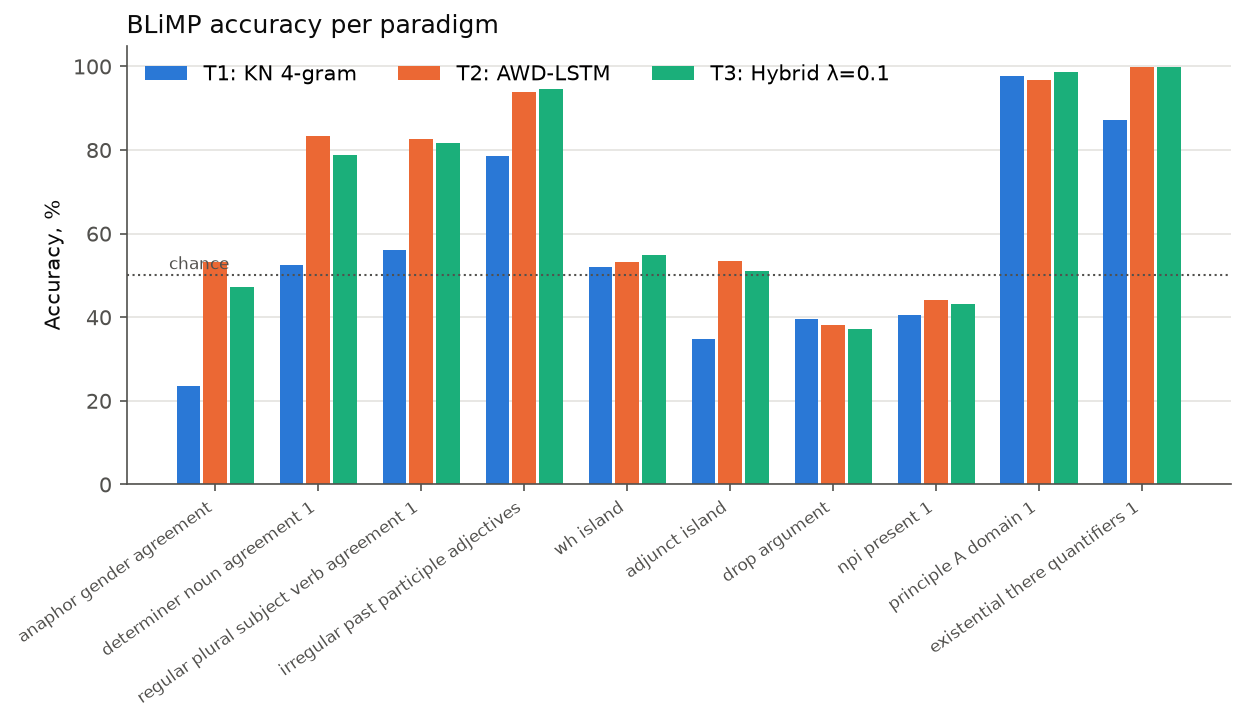

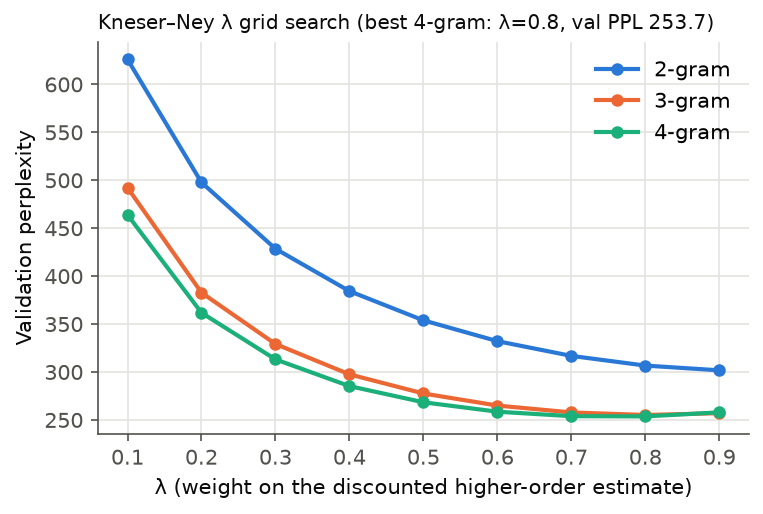

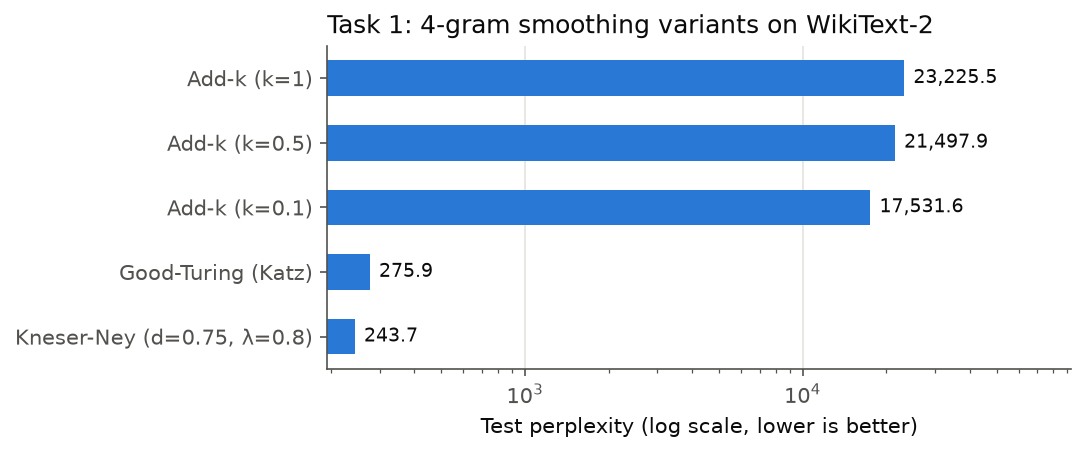

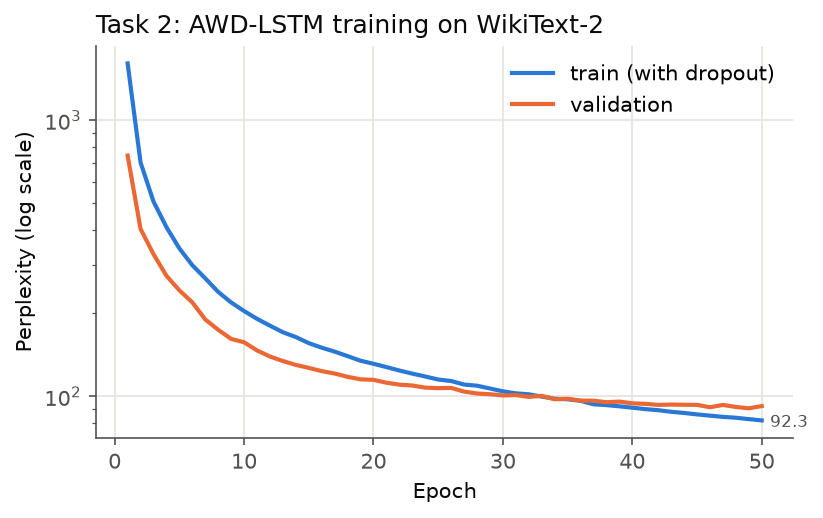

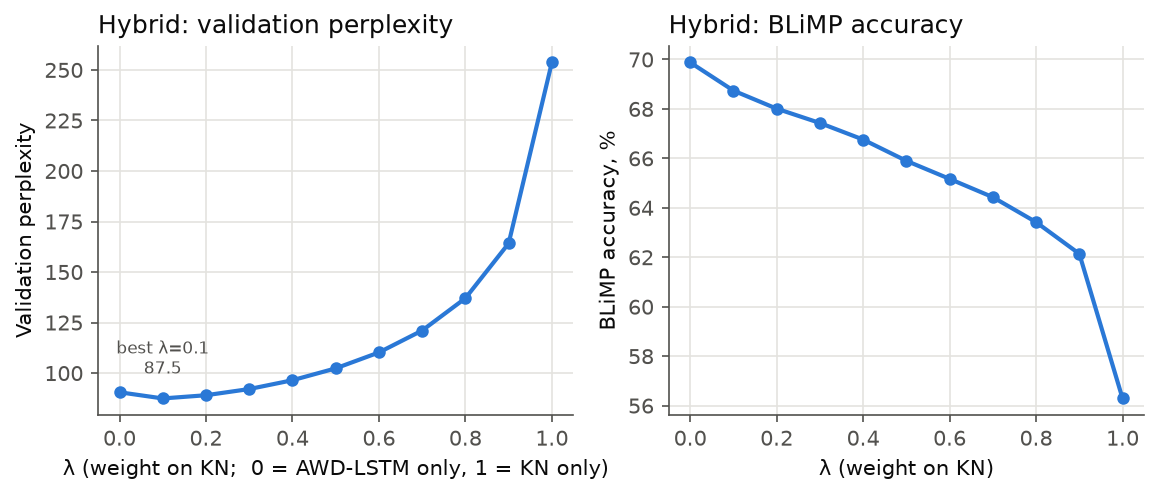

In [14]:
from IPython.display import Markdown, Image, display
for t in ('task1', 'task2', 'task3'):
    display(Markdown(open(f'{RES}/{t}_results.md').read()))
for f in sorted(os.listdir(f'{RES}/figures')):
    display(Image(f'{RES}/figures/{f}'))